In [1]:
import os, gc, json, time, random, hashlib
from io import BytesIO
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, callbacks, optimizers
from tensorflow.keras.applications import EfficientNetB0, ResNet50V2, MobileNetV2

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

IMG_SIZE, BATCH = 224, 32
AUTOTUNE = tf.data.AUTOTUNE
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("TF:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TF: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
BASE = Path("/kaggle/input/datasets/miraosama/oral-diseases-dataset/Oral Diseases Dataset")

CLASS_DIRS = {
    "Calculus":            BASE / "Calculus",
    "Caries":              BASE / "Data caries" / "caries orignal data set",
    "Gingivitis":          BASE / "Gingivitis",
    "Mouth_Ulcer":         BASE / "Mouth Ulcer" / "ulcer original dataset",
    "Tooth_Discoloration": BASE / "Tooth Discoloration" / "tooth discoloration original dataset",
    "Hypodontia":          BASE / "hypodontia",
}
AUG_DIRS = {
    "Caries":              BASE / "Data caries" / "caries augmented data set",
    "Mouth_Ulcer":         BASE / "Mouth Ulcer" / "Mouth_Ulcer_augmented_DataSet",
    "Tooth_Discoloration": BASE / "Tooth Discoloration" / "Tooth_discoloration_augmented_dataser",
}

for label, aug_dir in AUG_DIRS.items():
    print(f"{label:20s} original: {sorted(p.name for p in CLASS_DIRS[label].iterdir())[:3]}"
          f" | augmented: {sorted(p.name for p in aug_dir.iterdir())[:3]}")

rows = []
for label, folder in CLASS_DIRS.items():
    assert folder.exists(), f"Missing: {folder}"
    for f in folder.iterdir():
        if f.suffix.lower() in IMG_EXT:
            rows.append({"path": str(f), "label": label})

df = pd.DataFrame(rows)
print(df.shape)
print(df["label"].value_counts())

Caries               original: ['0.jpg', '1.jpg', '10.jpg'] | augmented: ['caries_0_1001.jpeg', 'caries_0_1005.jpeg', 'caries_0_1006.jpeg']
Mouth_Ulcer          original: ['0.jpg', '1.jpg', '10.jpg'] | augmented: ['Mouth_Ulcer_0_1.jpeg', 'Mouth_Ulcer_0_1003.jpeg', 'Mouth_Ulcer_0_1004.jpeg']
Tooth_Discoloration  original: ['0.jpg', '1.jpg', '10.jpg'] | augmented: ['Tooth_Discoloration_0_1.jpeg', 'Tooth_Discoloration_0_1001.jpeg', 'Tooth_Discoloration_0_1002.jpeg']
(5563, 2)
label
Gingivitis             2349
Calculus               1296
Hypodontia             1251
Mouth_Ulcer             265
Caries                  219
Tooth_Discoloration     183
Name: count, dtype: int64


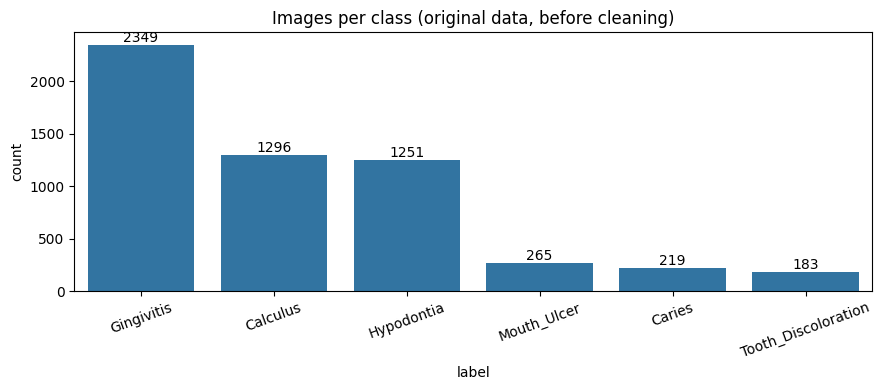

In [3]:
plt.figure(figsize=(9, 4))
ax = sns.countplot(data=df, x="label", order=df["label"].value_counts().index)
for c in ax.containers:
    ax.bar_label(c)
plt.xticks(rotation=20)
plt.title("Images per class (original data, before cleaning)")
plt.tight_layout(); plt.show()

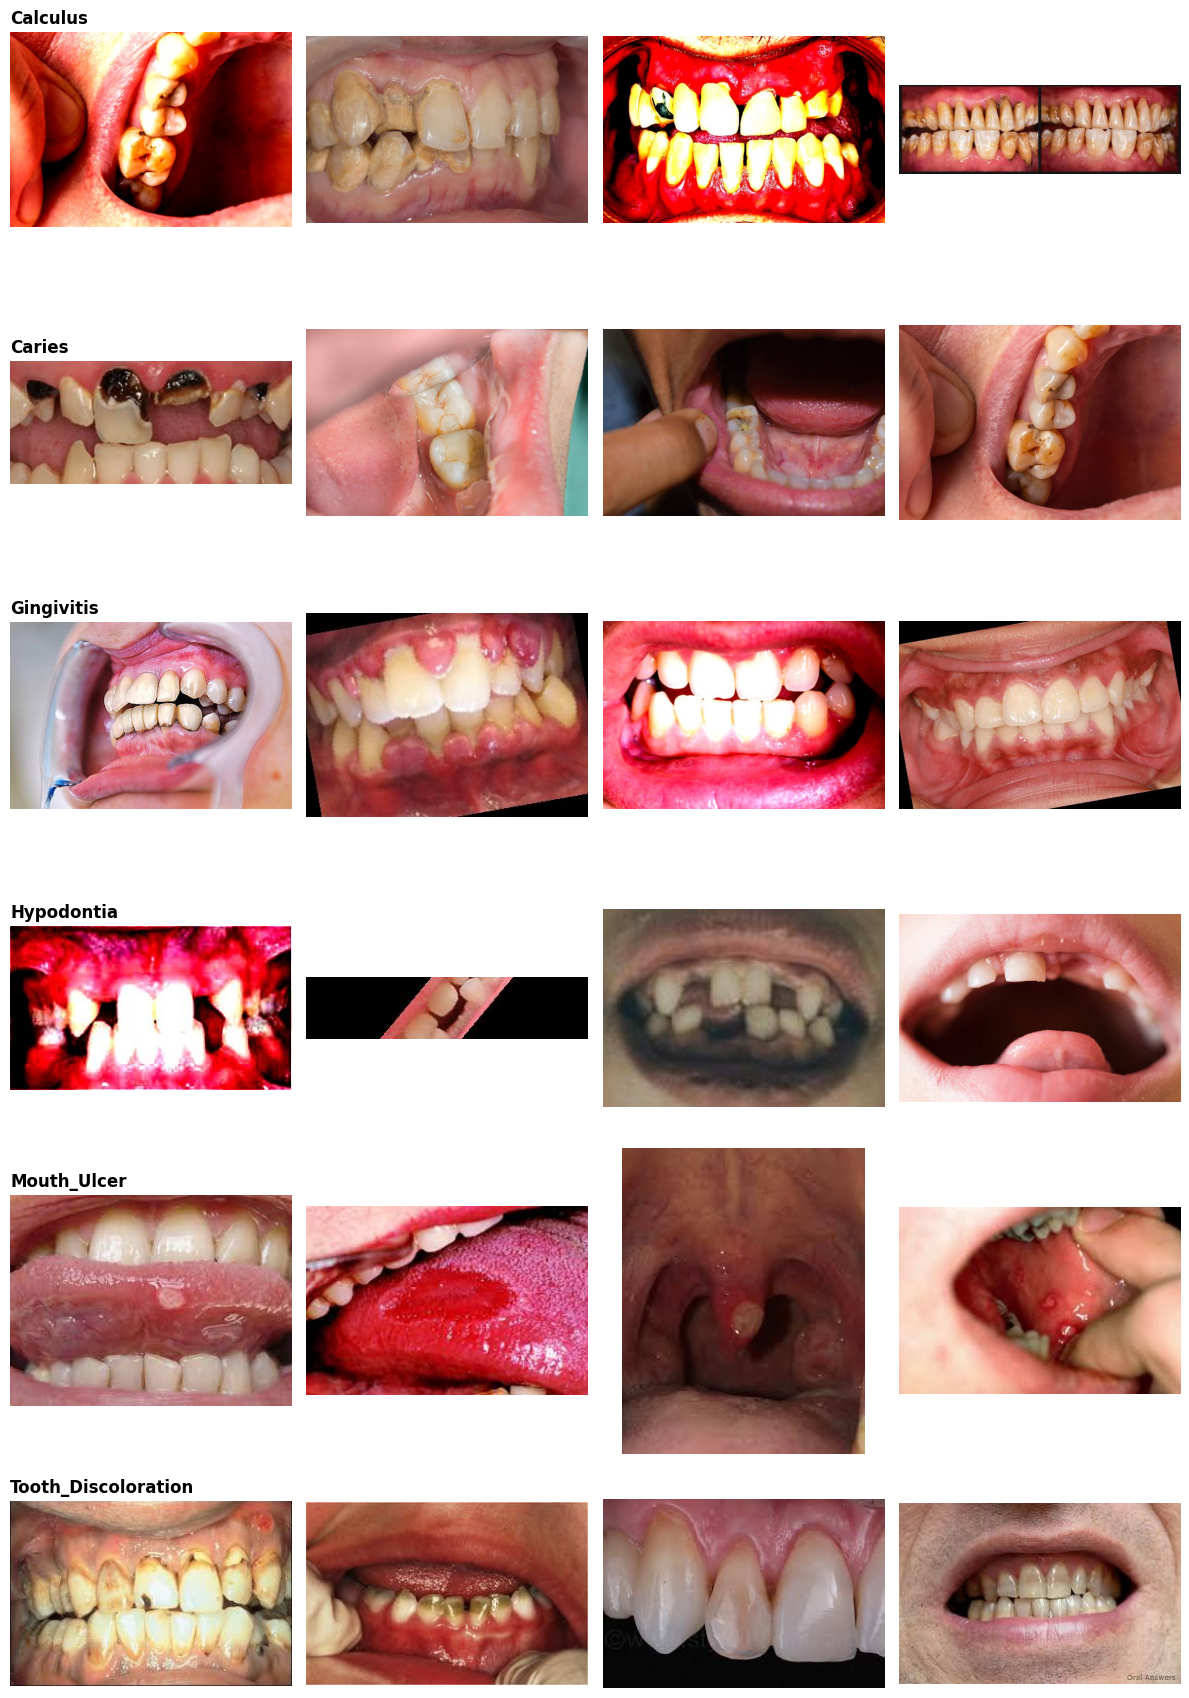

In [4]:
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))
for i, c in enumerate(classes):
    samples = df[df.label == c].sample(4, random_state=SEED)["path"]
    for j, p in enumerate(samples):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

In [5]:
def check(path):
    try:
        data = Path(path).read_bytes()
        md5 = hashlib.md5(data).hexdigest()
        with Image.open(BytesIO(data)) as im:
            im.load()
            w, h = im.size
        return w, h, md5, True
    except Exception:
        return None, None, None, False

with ThreadPoolExecutor(max_workers=16) as ex:
    res_chk = list(ex.map(check, df["path"]))

df[["w", "h", "md5", "ok"]] = pd.DataFrame(res_chk, index=df.index)
print("Corrupted:", (~df.ok).sum())
df = df[df.ok].copy()

dup_mask = df.duplicated("md5", keep=False)
print("Images in exact-duplicate groups:", dup_mask.sum())
cross = df[dup_mask].groupby("md5")["label"].nunique().gt(1).sum()
print("Duplicate groups spanning different classes:", cross)

Corrupted: 0
Images in exact-duplicate groups: 2439
Duplicate groups spanning different classes: 392


In [6]:
n_cls = df.groupby("md5")["label"].nunique()
conflict = n_cls[n_cls > 1].index
print("Conflicting groups:", len(conflict), "| images removed:", df["md5"].isin(conflict).sum())
df = df[~df["md5"].isin(conflict)]

before = len(df)
df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
print(f"Removed {before - len(df)} same-class duplicates -> {len(df)} images")
print(df["label"].value_counts())

class_names = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
df["y"] = df["label"].map(class_to_idx)
NUM_CLASSES = len(class_names)
json.dump(class_names, open("class_names.json", "w"))
print(class_to_idx)

Conflicting groups: 392 | images removed: 1510
Removed 546 same-class duplicates -> 3507 images
label
Gingivitis             1236
Hypodontia             1215
Calculus                449
Mouth_Ulcer             243
Caries                  191
Tooth_Discoloration     173
Name: count, dtype: int64
{'Calculus': 0, 'Caries': 1, 'Gingivitis': 2, 'Hypodontia': 3, 'Mouth_Ulcer': 4, 'Tooth_Discoloration': 5}


                         w      h  aspect
label                                    
Calculus             611.8  360.5     1.9
Caries               404.4  286.9     1.5
Gingivitis           565.2  366.8     1.6
Hypodontia           338.6  178.0     2.3
Mouth_Ulcer          322.1  231.8     1.4
Tooth_Discoloration  305.9  201.3     1.6
Images with a side < 64 px: 99 {'Hypodontia': 99}


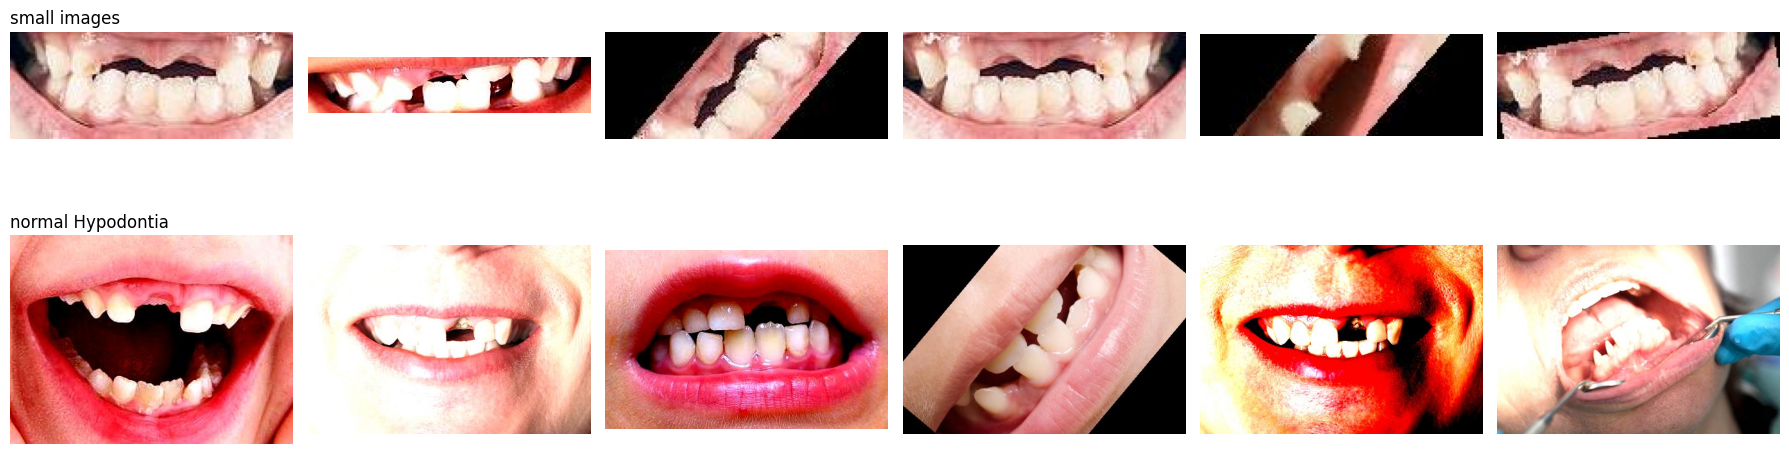

In [7]:
df["aspect"] = df.w / df.h
print(df.groupby("label")[["w", "h", "aspect"]].mean().round(1))

small = df[(df.w < 64) | (df.h < 64)]
print("Images with a side < 64 px:", len(small), small.label.value_counts().to_dict())

k = min(6, len(small))
normal = df[(df.label == "Hypodontia") & (df.h >= 200)].sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax in axes.ravel(): ax.axis("off")
for ax, p in zip(axes[0], small.sample(k, random_state=SEED).path): ax.imshow(Image.open(p))
for ax, p in zip(axes[1], normal.path): ax.imshow(Image.open(p))
axes[0, 0].set_title("small images", loc="left"); axes[1, 0].set_title("normal Hypodontia", loc="left")
plt.tight_layout(); plt.show()

In [8]:
feat_model = tf.keras.Sequential([
    layers.Input((IMG_SIZE, IMG_SIZE, 3)),
    layers.Rescaling(1/127.5, offset=-1),
    MobileNetV2(include_top=False, weights="imagenet", pooling="avg"),
])

def load_only(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE))

feat_ds = (tf.data.Dataset.from_tensor_slices(df["path"].values)
           .map(load_only, num_parallel_calls=AUTOTUNE).batch(64).prefetch(AUTOTUNE))
feats = feat_model.predict(feat_ds, verbose=1)
feats /= np.linalg.norm(feats, axis=1, keepdims=True)
sim = feats @ feats.T

for th in (0.85, 0.90, 0.93, 0.95):
    n, lab = connected_components(csr_matrix(sim >= th), directed=False)
    sizes = np.bincount(lab)
    cross = df.groupby(lab)["label"].nunique().gt(1).sum()
    print(f"th={th}: groups={n}, largest={sizes.max()}, cross-class groups={cross}")

I0000 00:00:1793022612.185169      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793022612.189062      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2026-10-26 13:50:28.457634: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 13:50:28.596405: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1793022630.251792     161 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


54/55 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step

2026-10-26 13:50:45.029417: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-26 13:50:45.166919: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


55/55 ━━━━━━━━━━━━━━━━━━━━ 33s 304ms/step
th=0.85: groups=1864, largest=47, cross-class groups=6
th=0.9: groups=2622, largest=9, cross-class groups=1
th=0.93: groups=3018, largest=9, cross-class groups=1
th=0.95: groups=3309, largest=6, cross-class groups=0


In [9]:
TH = 0.90
_, groups = connected_components(csr_matrix(sim >= TH), directed=False)

multi = df.groupby(groups)["label"].nunique()
bad = multi[multi > 1].index
keep = ~np.isin(groups, bad)
print(f"Dropping {(~keep).sum()} images from {len(bad)} cross-class group(s)")
df, groups, feats = df[keep].reset_index(drop=True), groups[keep], feats[keep]

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [idx for _, idx in sgkf.split(df, df["y"], groups)]
test_idx, val_idx = folds[0], folds[1]
train_idx = np.setdiff1d(np.arange(len(df)), np.r_[test_idx, val_idx])

assert not set(groups[train_idx]) & set(groups[val_idx])
assert not set(groups[train_idx]) & set(groups[test_idx])
assert not set(groups[val_idx]) & set(groups[test_idx])

train_df, val_df, test_df = (df.iloc[i] for i in (train_idx, val_idx, test_idx))

summary = pd.DataFrame({"train": train_df.label.value_counts(),
                        "val":   val_df.label.value_counts(),
                        "test":  test_df.label.value_counts()}).loc[class_names]
print(summary, "\n", summary.sum())

rnd = np.random.RandomState(SEED).permutation(len(df))
r_test, r_train = rnd[:len(test_idx)], rnd[len(test_idx) + len(val_idx):]
print("mean max-sim test->train | group split :", (feats[test_idx] @ feats[train_idx].T).max(1).mean().round(3))
print("mean max-sim test->train | random split:", (feats[r_test] @ feats[r_train].T).max(1).mean().round(3))

train_df.to_csv("train.csv", index=False)
val_df.to_csv("val.csv", index=False)
test_df.to_csv("test.csv", index=False)

Dropping 5 images from 1 cross-class group(s)
                     train  val  test
label                                
Calculus               314   62    73
Caries                 135   26    29
Gingivitis             876  183   173
Hypodontia             879  157   179
Mouth_Ulcer            175   36    32
Tooth_Discoloration    124   22    27 
 train    2503
val       486
test      513
dtype: int64
mean max-sim test->train | group split : 0.818
mean max-sim test->train | random split: 0.856


In [10]:
train_df = pd.read_csv("train.csv"); val_df = pd.read_csv("val.csv"); test_df = pd.read_csv("test.csv")

def load_img(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))       
    return img, tf.one_hot(y, NUM_CLASSES)

def make_ds(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["y"].values))
    ds = ds.map(load_img, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(1000, seed=SEED)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["y"])
class_weight = dict(enumerate(cw))
print(dict(zip(class_names, cw.round(2))))

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

{'Calculus': np.float64(1.33), 'Caries': np.float64(3.09), 'Gingivitis': np.float64(0.48), 'Hypodontia': np.float64(0.47), 'Mouth_Ulcer': np.float64(2.38), 'Tooth_Discoloration': np.float64(3.36)}


In [11]:
def get_callbacks(save_as=None, patience=10):
    cbs = [
        callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=4, min_lr=1e-6),
    ]
    if save_as:
        cbs.append(callbacks.ModelCheckpoint(f"{save_as}.keras", monitor="val_loss", save_best_only=True))
    return cbs

def predict_labels(model, ds):
    y_true = np.concatenate([np.argmax(y, 1) for _, y in ds])
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    return y_true, y_pred

def evaluate(model, ds, title, plot=True):
    y_true, y_pred = predict_labels(model, ds)
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    if plot:
        plt.figure(figsize=(7, 5))
        sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
                    xticklabels=class_names, yticklabels=class_names)
        plt.title(title); plt.ylabel("True"); plt.xlabel("Predicted"); plt.show()
    return f1_score(y_true, y_pred, average="macro")

def full_metrics(model, ds):
    model.predict(ds.take(1), verbose=0)                      
    y_true = np.concatenate([np.argmax(y, 1) for _, y in ds])
    t0 = time.time()
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    ms = (time.time() - t0) / len(y_true) * 1000
    return (y_true == y_pred).mean(), f1_score(y_true, y_pred, average="macro"), ms

registry = {}
def register(name, model, hists, secs):
    registry[name] = {"model": model, "hists": hists, "minutes": secs / 60}

Epoch 1/60
79/79 - 20s - 251ms/step - accuracy: 0.3855 - loss: 1.6450 - val_accuracy: 0.1214 - val_loss: 2.1801 - learning_rate: 0.0010
Epoch 2/60
79/79 - 10s - 127ms/step - accuracy: 0.3748 - loss: 1.5724 - val_accuracy: 0.0741 - val_loss: 2.6130 - learning_rate: 0.0010
Epoch 3/60
79/79 - 10s - 128ms/step - accuracy: 0.3268 - loss: 1.5628 - val_accuracy: 0.0741 - val_loss: 2.7746 - learning_rate: 0.0010
Epoch 4/60
79/79 - 10s - 129ms/step - accuracy: 0.3356 - loss: 1.5517 - val_accuracy: 0.0741 - val_loss: 3.0720 - learning_rate: 0.0010
Epoch 5/60
79/79 - 10s - 131ms/step - accuracy: 0.3532 - loss: 1.4438 - val_accuracy: 0.1523 - val_loss: 2.5805 - learning_rate: 0.0010
Epoch 6/60
79/79 - 10s - 133ms/step - accuracy: 0.3460 - loss: 1.4881 - val_accuracy: 0.1440 - val_loss: 2.5460 - learning_rate: 3.0000e-04
Epoch 7/60
79/79 - 11s - 135ms/step - accuracy: 0.3712 - loss: 1.3772 - val_accuracy: 0.2037 - val_loss: 2.0931 - learning_rate: 3.0000e-04
Epoch 8/60
79/79 - 11s - 137ms/step - ac

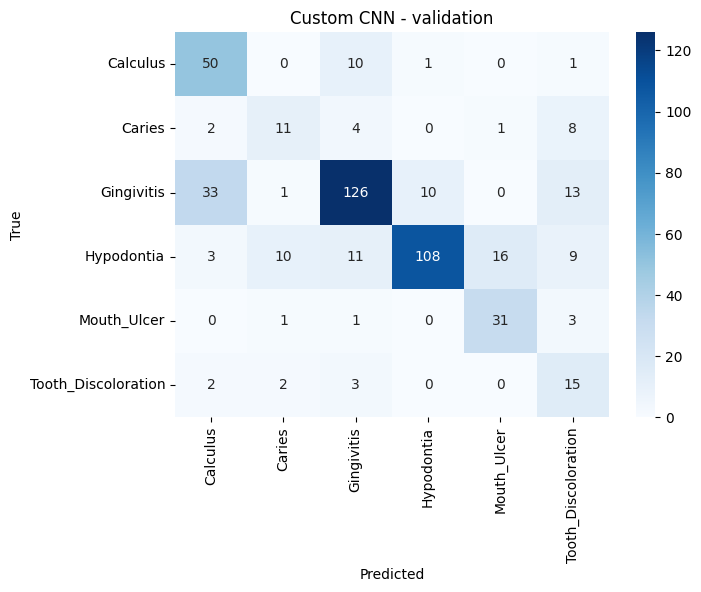

In [12]:
def conv_block(x, f):
    x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return layers.MaxPooling2D()(x)

def build_cnn(lr=1e-3, dropout=0.5, dense=256):
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = layers.Rescaling(1/255)(x)
    for f in (32, 64, 128, 256):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    m = tf.keras.Model(inp, out, name="custom_cnn")
    m.compile(optimizers.Adam(lr), "categorical_crossentropy", metrics=["accuracy"])
    return m

t0 = time.time()
cnn = build_cnn()
history_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=60, class_weight=class_weight,
                      callbacks=get_callbacks("cnn_best"), verbose=2)
register("Custom CNN", cnn, [history_cnn], time.time() - t0)
evaluate(cnn, val_ds, "Custom CNN - validation");

In [13]:
BACKBONES = {
    "EfficientNetB0": (EfficientNetB0, False),  
    "ResNet50V2":     (ResNet50V2,     True),   
    "MobileNetV2":    (MobileNetV2,    True),
}

def build_pretrained(name, dropout=0.3):
    Base, needs_scale = BACKBONES[name]
    base = Base(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False

    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    if needs_scale:
        x = layers.Rescaling(1/127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inp, out, name=name), base

def train_pretrained(name, dropout=0.3, lr1=1e-3, lr2=1e-5, unfreeze=30,
                     e1=15, e2=30, save_as=None, verbose=2):
    t0 = time.time()
    model, base = build_pretrained(name, dropout)

    model.compile(optimizers.Adam(lr1), "categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=e1, class_weight=class_weight,
                   callbacks=get_callbacks(), verbose=verbose)

    base.trainable = True
    for l in base.layers[:-unfreeze]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    model.compile(optimizers.Adam(lr2), "categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=e2, class_weight=class_weight,
                   callbacks=get_callbacks(save_as), verbose=verbose)
    return model, [h1, h2], time.time() - t0

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15


E0000 00:00:1793023149.864497      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


79/79 - 21s - 265ms/step - accuracy: 0.4423 - loss: 1.6032 - val_accuracy: 0.5947 - val_loss: 1.0657 - learning_rate: 0.0010
Epoch 2/15
79/79 - 7s - 94ms/step - accuracy: 0.6249 - loss: 1.1443 - val_accuracy: 0.6749 - val_loss: 0.8659 - learning_rate: 0.0010
Epoch 3/15
79/79 - 8s - 95ms/step - accuracy: 0.6816 - loss: 0.9574 - val_accuracy: 0.7305 - val_loss: 0.7372 - learning_rate: 0.0010
Epoch 4/15
79/79 - 8s - 96ms/step - accuracy: 0.7307 - loss: 0.8204 - val_accuracy: 0.7469 - val_loss: 0.6673 - learning_rate: 0.0010
Epoch 5/15
79/79 - 8s - 95ms/step - accuracy: 0.7383 - loss: 0.7904 - val_accuracy: 0.7366 - val_loss: 0.6743 - learning_rate: 0.0010
Epoch 6/15
79/79 - 8s - 95ms/step - accuracy: 0.7607 - loss: 0.7287 - val_accuracy: 0.7551 - val_loss: 0.6110 - learning_rate: 0.0010
Epoch 7/15
79/79 - 7s - 93ms/step - accuracy: 0.7679 - loss: 0.6802 - val_accuracy: 0.7634 - val_loss: 0.5781 - learning_rate: 0.0010
Epoch 8/15
79/79 - 7s - 93ms/step - accuracy: 0.7647 - loss: 0.6960 - v

E0000 00:00:1793023276.257199      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


79/79 - 22s - 284ms/step - accuracy: 0.8242 - loss: 0.5095 - val_accuracy: 0.8416 - val_loss: 0.4437 - learning_rate: 1.0000e-05
Epoch 2/30
79/79 - 9s - 112ms/step - accuracy: 0.8390 - loss: 0.4702 - val_accuracy: 0.8498 - val_loss: 0.4261 - learning_rate: 1.0000e-05
Epoch 3/30
79/79 - 9s - 113ms/step - accuracy: 0.8458 - loss: 0.4333 - val_accuracy: 0.8436 - val_loss: 0.4233 - learning_rate: 1.0000e-05
Epoch 4/30
79/79 - 9s - 113ms/step - accuracy: 0.8430 - loss: 0.4359 - val_accuracy: 0.8436 - val_loss: 0.4183 - learning_rate: 1.0000e-05
Epoch 5/30
79/79 - 9s - 112ms/step - accuracy: 0.8426 - loss: 0.4299 - val_accuracy: 0.8498 - val_loss: 0.4061 - learning_rate: 1.0000e-05
Epoch 6/30
79/79 - 9s - 111ms/step - accuracy: 0.8562 - loss: 0.3922 - val_accuracy: 0.8539 - val_loss: 0.4034 - learning_rate: 1.0000e-05
Epoch 7/30
79/79 - 8s - 100ms/step - accuracy: 0.8438 - loss: 0.4355 - val_accuracy: 0.8416 - val_loss: 0.4123 - learning_rate: 1.0000e-05
Epoch 8/30
79/79 - 8s - 99ms/step - a

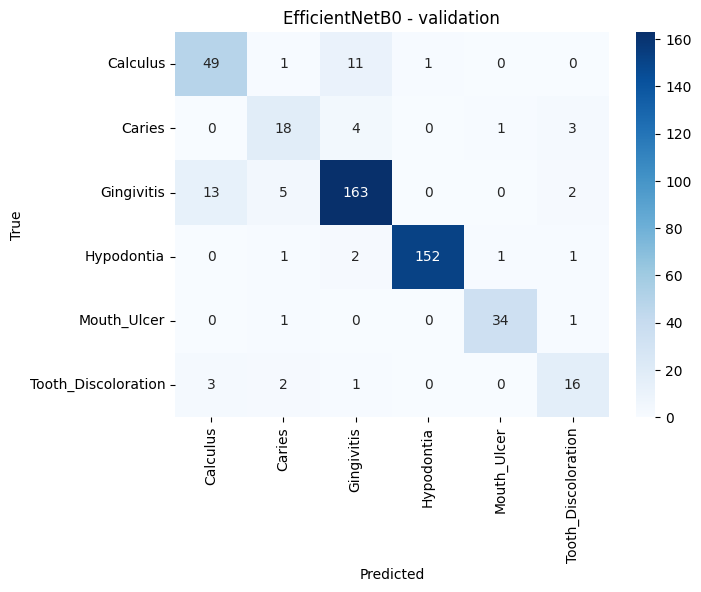

In [14]:
m, hs, secs = train_pretrained("EfficientNetB0", save_as="EfficientNetB0_best")
register("EfficientNetB0", m, hs, secs)
evaluate(m, val_ds, "EfficientNetB0 - validation");

Epoch 1/15
79/79 - 13s - 159ms/step - accuracy: 0.4227 - loss: 2.0104 - val_accuracy: 0.6605 - val_loss: 0.9994 - learning_rate: 0.0010
Epoch 2/15
79/79 - 6s - 71ms/step - accuracy: 0.5913 - loss: 1.2671 - val_accuracy: 0.7181 - val_loss: 0.7579 - learning_rate: 0.0010
Epoch 3/15
79/79 - 6s - 71ms/step - accuracy: 0.6572 - loss: 1.0436 - val_accuracy: 0.7490 - val_loss: 0.6598 - learning_rate: 0.0010
Epoch 4/15
79/79 - 6s - 71ms/step - accuracy: 0.6956 - loss: 0.8881 - val_accuracy: 0.7531 - val_loss: 0.6634 - learning_rate: 0.0010
Epoch 5/15
79/79 - 6s - 73ms/step - accuracy: 0.7207 - loss: 0.8142 - val_accuracy: 0.7798 - val_loss: 0.5922 - learning_rate: 0.0010
Epoch 6/15
79/79 - 6s - 73ms/step - accuracy: 0.7515 - loss: 0.7569 - val_accuracy: 0.7984 - val_loss: 0.5605 - learning_rate: 0.0010
Epoch 7/15
79/79 - 6s - 70ms/step - accuracy: 0.7511 - loss: 0.7108 - val_accuracy: 0.7613 - val_loss: 0.6221 - learning_rate: 0.0010
Epoch 8/15
79/79 - 6s - 70ms/step - accuracy: 0.7791 - loss:

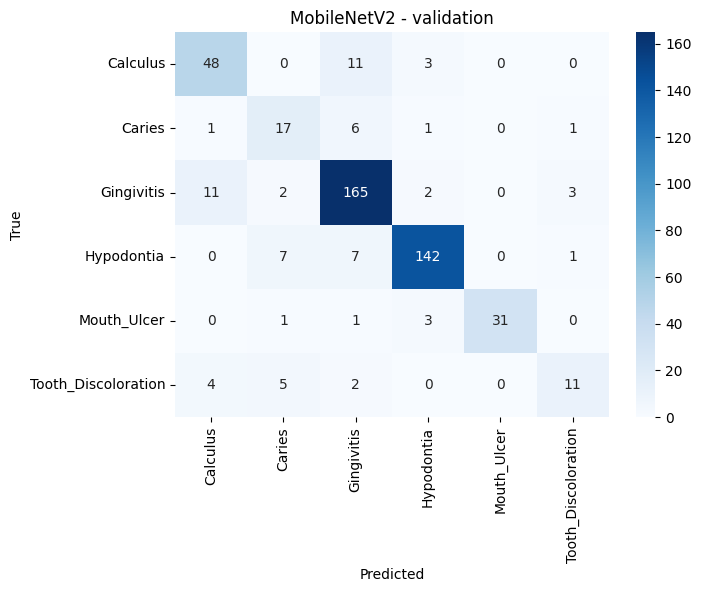

In [15]:
m, hs, secs = train_pretrained("MobileNetV2", save_as="MobileNetV2_best")
register("MobileNetV2", m, hs, secs)
evaluate(m, val_ds, "MobileNetV2 - validation");

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
79/79 - 21s - 269ms/step - accuracy: 0.4583 - loss: 1.9892 - val_accuracy: 0.5391 - val_loss: 1.2056 - learning_rate: 0.0010
Epoch 2/15
79/79 - 12s - 147ms/step - accuracy: 0.5805 - loss: 1.3448 - val_accuracy: 0.5967 - val_loss: 1.0187 - learning_rate: 0.0010
Epoch 3/15
79/79 - 12s - 150ms/step - accuracy: 0.6660 - loss: 1.0708 - val_accuracy: 0.6955 - val_loss: 0.8110 - learning_rate: 0.0010
Epoch 4/15
79/79 - 11s - 145ms/step - accuracy: 0.6996 - loss: 0.9326 - val_accuracy: 0.6852 - val_loss: 0.8409 - learning_rate: 0.0010
Epoch 5/15
79/79 - 11s - 143ms/step - accuracy: 0.7163 - loss: 0.8434 - val_accuracy: 0.7387 - val_loss: 0.6805 - learning_rate: 0.0010
Epoch 6/15
79/79 - 11s - 141ms/step - accuracy: 0.7551 - loss: 0.7675 - val_accuracy: 0.7881 - val_loss: 0.6150 - learning_rate: 0.0010
Epoch 7/15
79/79 - 11s - 141ms/step - accuracy: 0.7551 - loss: 0.7140 - val_accuracy: 0.8107 - val_loss: 0.5197 - learning_rate: 0.00

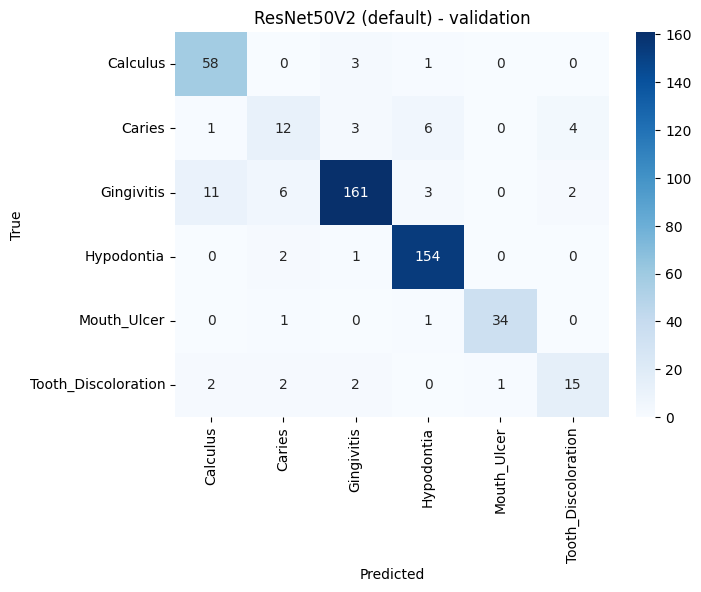

In [16]:
m, hs, secs = train_pretrained("ResNet50V2", save_as="ResNet50V2_best")
register("ResNet50V2 (default)", m, hs, secs)
evaluate(m, val_ds, "ResNet50V2 (default) - validation");

In [17]:
tuning_configs = [
    {"dropout": 0.3, "lr1": 1e-3, "lr2": 1e-5, "unfreeze": 30},    
    {"dropout": 0.5, "lr1": 1e-3, "lr2": 1e-5, "unfreeze": 100},
    {"dropout": 0.5, "lr1": 1e-3, "lr2": 1e-4, "unfreeze": 60},
    {"dropout": 0.5, "lr1": 1e-3, "lr2": 1e-4, "unfreeze": 100},
    {"dropout": 0.5, "lr1": 1e-3, "lr2": 1e-4, "unfreeze": 150},  
]

tuning_log = []
for i, cfg in enumerate(tuning_configs, 1):
    print(f"\n=== Trial {i}/{len(tuning_configs)}: {cfg}", flush=True)
    m, _, secs = train_pretrained("ResNet50V2", e1=8, e2=15, verbose=0, **cfg)
    acc, f1, _ = full_metrics(m, val_ds)
    tuning_log.append({"trial": i, **cfg, "val_acc": round(acc, 4),
                       "val_macro_f1": round(f1, 4), "minutes": round(secs / 60, 1)})
    pd.DataFrame(tuning_log).to_csv("tuning_log_groupsplit.csv", index=False)
    print(f"-> val macro-F1 = {f1:.4f} | {secs/60:.1f} min", flush=True)
    del m; gc.collect()

tuning_df = pd.DataFrame(tuning_log).sort_values("val_macro_f1", ascending=False)
tuning_df


=== Trial 1/5: {'dropout': 0.3, 'lr1': 0.001, 'lr2': 1e-05, 'unfreeze': 30}
-> val macro-F1 = 0.8072 | 5.4 min

=== Trial 2/5: {'dropout': 0.5, 'lr1': 0.001, 'lr2': 1e-05, 'unfreeze': 100}
-> val macro-F1 = 0.8530 | 6.5 min

=== Trial 3/5: {'dropout': 0.5, 'lr1': 0.001, 'lr2': 0.0001, 'unfreeze': 60}
-> val macro-F1 = 0.8410 | 5.7 min

=== Trial 4/5: {'dropout': 0.5, 'lr1': 0.001, 'lr2': 0.0001, 'unfreeze': 100}
-> val macro-F1 = 0.8679 | 6.5 min

=== Trial 5/5: {'dropout': 0.5, 'lr1': 0.001, 'lr2': 0.0001, 'unfreeze': 150}
-> val macro-F1 = 0.8284 | 7.4 min


,trial,dropout,lr1,lr2,unfreeze,val_acc,val_macro_f1,minutes
3,4,0.5,0.001,0.00010,100,0.9198,0.8679,6.5
1,2,0.5,0.001,0.00001,100,0.9177,0.8530,6.5
2,3,0.5,0.001,0.00010,60,0.9177,0.8410,5.7
4,5,0.5,0.001,0.00010,150,0.8848,0.8284,7.4
0,1,0.3,0.001,0.00001,30,0.8848,0.8072,5.4


In [18]:
if os.path.exists("tuning_log.csv"):
    print("First search (earlier random split - for reference only):")
    display(pd.read_csv("tuning_log.csv").sort_values("val_macro_f1", ascending=False))

Best config: {'dropout': 0.5, 'lr1': 0.001, 'lr2': 0.0001, 'unfreeze': 100}
Epoch 1/15
79/79 - 19s - 243ms/step - accuracy: 0.3903 - loss: 2.4049 - val_accuracy: 0.5720 - val_loss: 1.1831 - learning_rate: 0.0010
Epoch 2/15
79/79 - 12s - 146ms/step - accuracy: 0.5465 - loss: 1.4203 - val_accuracy: 0.6502 - val_loss: 0.9680 - learning_rate: 0.0010
Epoch 3/15
79/79 - 12s - 150ms/step - accuracy: 0.6017 - loss: 1.2247 - val_accuracy: 0.6749 - val_loss: 0.9134 - learning_rate: 0.0010
Epoch 4/15
79/79 - 12s - 150ms/step - accuracy: 0.6456 - loss: 1.0965 - val_accuracy: 0.7160 - val_loss: 0.8180 - learning_rate: 0.0010
Epoch 5/15
79/79 - 11s - 145ms/step - accuracy: 0.6732 - loss: 0.9676 - val_accuracy: 0.7243 - val_loss: 0.7841 - learning_rate: 0.0010
Epoch 6/15
79/79 - 11s - 142ms/step - accuracy: 0.7020 - loss: 0.9361 - val_accuracy: 0.7634 - val_loss: 0.6784 - learning_rate: 0.0010
Epoch 7/15
79/79 - 11s - 139ms/step - accuracy: 0.6932 - loss: 0.9317 - val_accuracy: 0.7531 - val_loss: 0.6

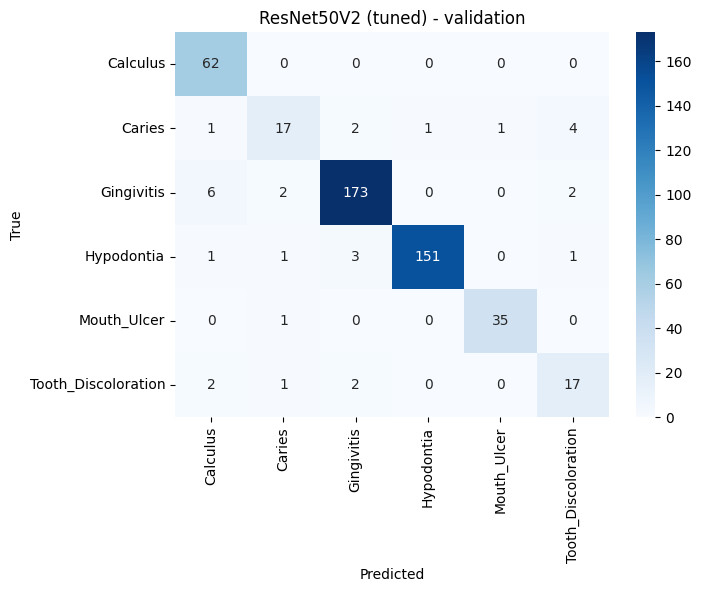

In [19]:
best_cfg = {k: (int(v) if k == "unfreeze" else float(v))
            for k, v in tuning_df.iloc[0][["dropout", "lr1", "lr2", "unfreeze"]].items()}
print("Best config:", best_cfg)

res_tuned, hs, secs = train_pretrained("ResNet50V2", save_as="ResNet50V2_tuned_best", **best_cfg)
register("ResNet50V2 (tuned)", res_tuned, hs, secs)
evaluate(res_tuned, val_ds, "ResNet50V2 (tuned) - validation");

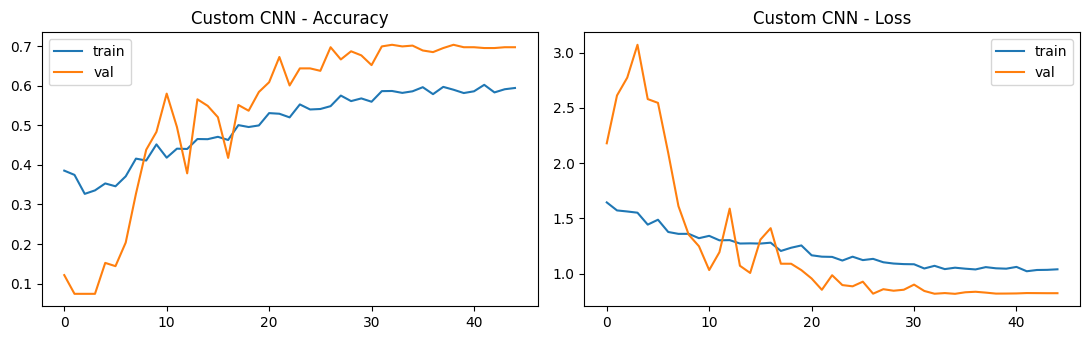

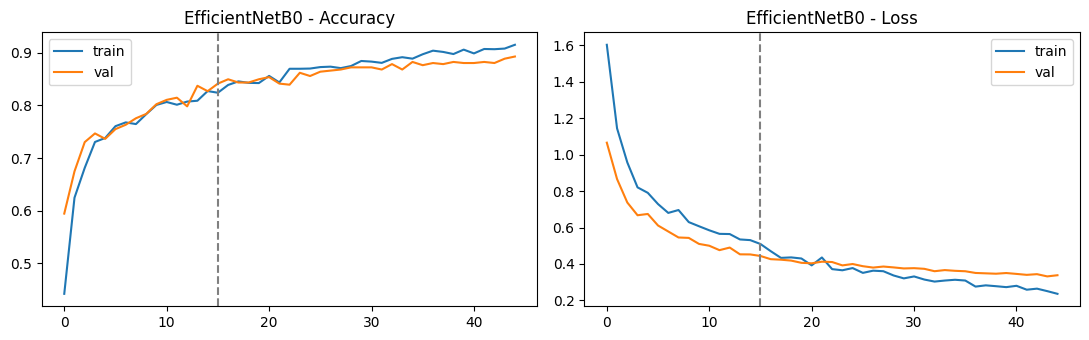

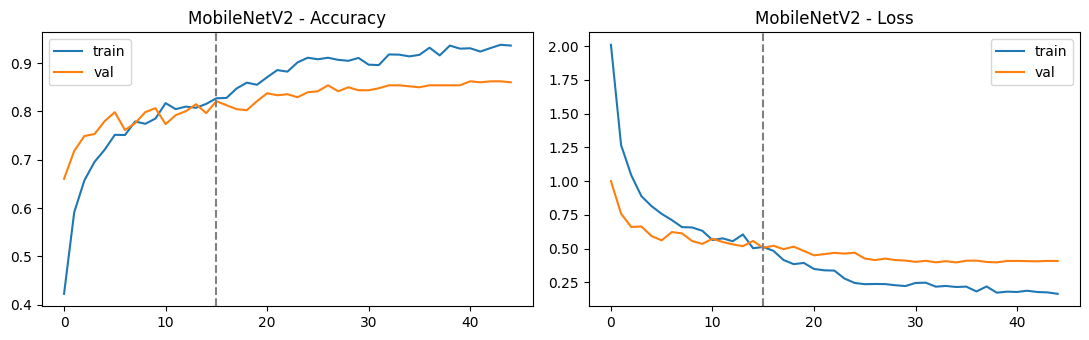

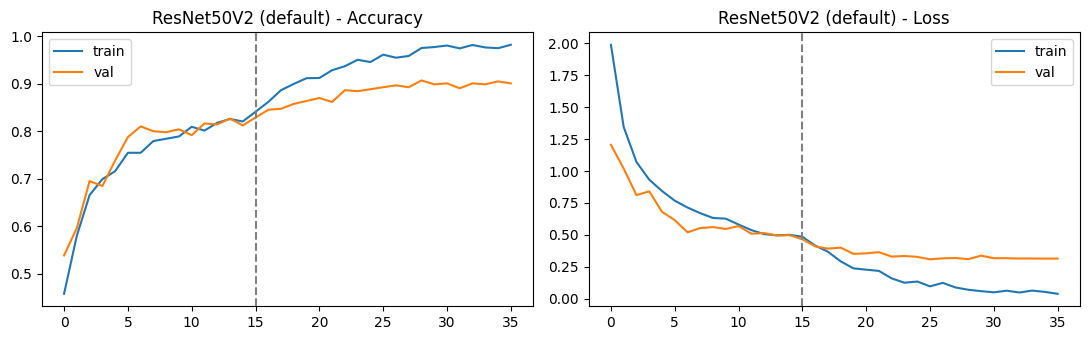

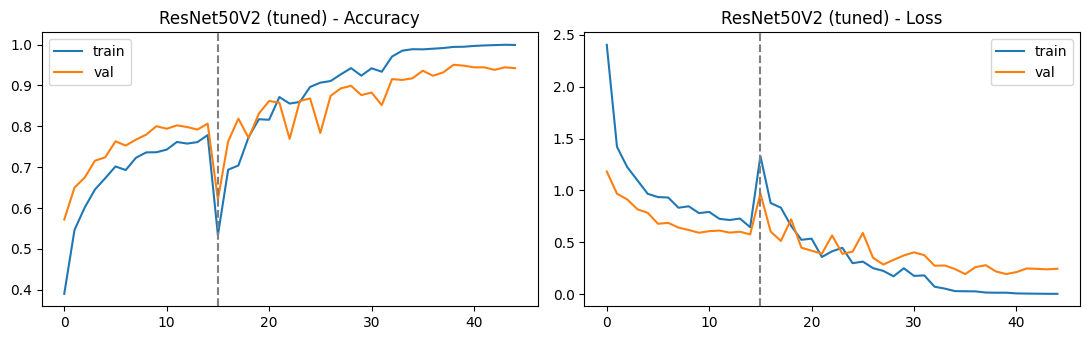

In [20]:
def plot_history(name, hists):
    acc  = sum([h.history["accuracy"] for h in hists], [])
    vacc = sum([h.history["val_accuracy"] for h in hists], [])
    loss = sum([h.history["loss"] for h in hists], [])
    vloss = sum([h.history["val_loss"] for h in hists], [])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for a, (tr, va, t) in zip(ax, [(acc, vacc, "Accuracy"), (loss, vloss, "Loss")]):
        a.plot(tr, label="train"); a.plot(va, label="val"); a.set_title(f"{name} - {t}"); a.legend()
        if len(hists) == 2:
            a.axvline(len(hists[0].history["loss"]), ls="--", c="gray")  
    plt.tight_layout(); plt.show()

for name, r in registry.items():
    plot_history(name, r["hists"])

In [21]:
rows = []
for name, r in registry.items():
    v_acc, v_f1, _  = full_metrics(r["model"], val_ds)
    t_acc, t_f1, ms = full_metrics(r["model"], test_ds)
    rows.append({"Model": name,
                 "Val Acc": round(v_acc, 4), "Val Macro-F1": round(v_f1, 4),
                 "Test Acc": round(t_acc, 4), "Test Macro-F1": round(t_f1, 4),
                 "Params (M)": round(r["model"].count_params() / 1e6, 2),
                 "Train (min)": round(r["minutes"], 1),
                 "Inference (ms/img)": round(ms, 2)})

comparison = pd.DataFrame(rows).sort_values("Val Macro-F1", ascending=False).reset_index(drop=True)
comparison.to_csv("comparison.csv", index=False)
best_name = comparison.loc[0, "Model"]
print("Best model (by validation macro-F1):", best_name)
comparison

Best model (by validation macro-F1): ResNet50V2 (tuned)


,Model,Val Acc,Val Macro-F1,Test Acc,Test Macro-F1,Params (M),Train (min),Inference (ms/img)
0,ResNet50V2 (tuned),0.9362,0.8793,0.9318,0.9055,23.58,12.7,3.66
1,EfficientNetB0,0.8889,0.8284,0.8811,0.8447,4.06,6.6,3.16
2,ResNet50V2 (default),0.8930,0.8133,0.9045,0.8538,23.58,8.3,4.43
3,MobileNetV2,0.8519,0.7758,0.8655,0.8338,2.27,4.8,2.08
4,Custom CNN,0.7016,0.6297,0.6296,0.5501,0.46,8.1,1.27


                     precision    recall  f1-score   support

           Calculus      0.873     0.945     0.908        73
             Caries      0.828     0.828     0.828        29
         Gingivitis      0.947     0.936     0.942       173
         Hypodontia      0.971     0.950     0.960       179
        Mouth_Ulcer      1.000     0.875     0.933        32
Tooth_Discoloration      0.806     0.926     0.862        27

           accuracy                          0.932       513
          macro avg      0.904     0.910     0.906       513
       weighted avg      0.934     0.932     0.932       513



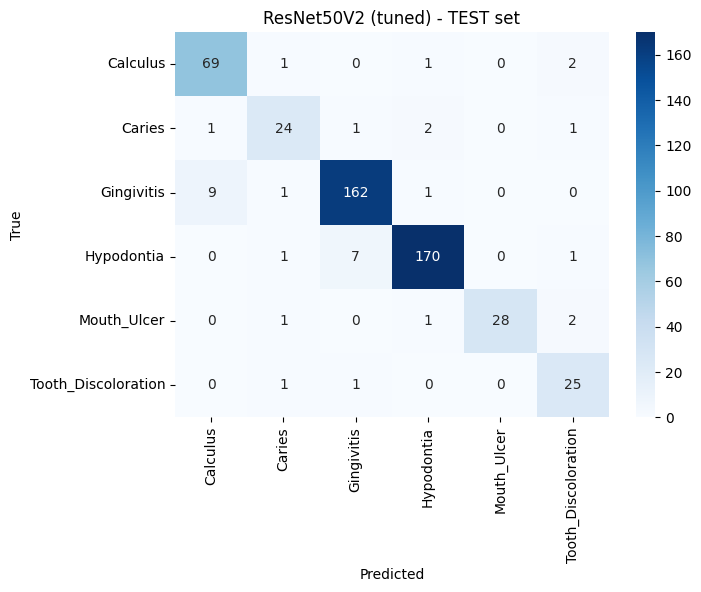

In [22]:
best_model = registry[best_name]["model"]
evaluate(best_model, test_ds, f"{best_name} - TEST set");

In [23]:
best_model.save("best_model.keras")
json.dump(class_names, open("class_names.json", "w"))

reloaded = tf.keras.models.load_model("best_model.keras", compile=False)
x, _ = next(iter(test_ds))
diff = np.abs(best_model.predict(x[:8], verbose=0) - reloaded.predict(x[:8], verbose=0)).max()
print("max prediction difference after reload:", diff)
print("expected input:", best_model.input_shape, "(raw 0-255 pixels, no extra preprocessing)")
print("classes:", class_names)

max prediction difference after reload: 0.0
expected input: (None, 224, 224, 3) (raw 0-255 pixels, no extra preprocessing)
classes: ['Calculus', 'Caries', 'Gingivitis', 'Hypodontia', 'Mouth_Ulcer', 'Tooth_Discoloration']


In [25]:
import shutil, os
os.makedirs("samples", exist_ok=True)
for c in class_names:
    for i, p in enumerate(test_df[test_df.label == c]["path"].head(3)):
        shutil.copy(p, f"samples/{c}_{i}{os.path.splitext(p)[1]}")
shutil.make_archive("samples", "zip", "samples")
print(os.listdir("samples"))

['Caries_1.jpg', 'Mouth_Ulcer_0.jpg', 'Gingivitis_0.jpg', 'Calculus_1.jpg', 'Hypodontia_1.JPG', 'Calculus_0.jpg', 'Calculus_2.jpg', 'Tooth_Discoloration_2.jpg', 'Tooth_Discoloration_1.jpg', 'Caries_2.jpg', 'Gingivitis_2.jpg', 'Hypodontia_0.JPG', 'Mouth_Ulcer_2.jpg', 'Tooth_Discoloration_0.jpg', 'Gingivitis_1.jpg', 'Hypodontia_2.JPG', 'Caries_0.jpg', 'Mouth_Ulcer_1.jpg']


1. Experimental setup

All five models were trained on the same leakage-controlled split. Exact duplicates were removed, along with images that appeared under conflicting labels. Near-duplicates were grouped with StratifiedGroupKFold, so the split was 2,503 train, 486 validation and 513 test images. All models used the same augmentation and class weights. The best model was selected by validation macro-F1, because the classes are imbalanced, and then reported on the untouched test set.

2. Results

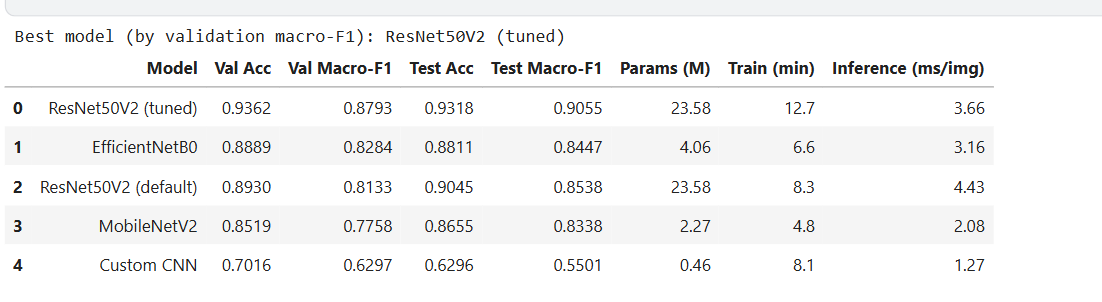


3. Discussion

Pretrained vs. custom CNN. Every pretrained model clearly outperformed the custom CNN (test macro-F1 0.83–0.91 vs. 0.55). The custom CNN has only 0.46M parameters and learns from scratch on about 2.5k training images. Its training curve was also unstable in the first epochs. The pretrained backbones start from ImageNet features (edges, textures, colours) that transfer well to oral photographs, so they need far less data. The custom CNN still serves as a useful baseline and is the fastest model (1.27 ms/img), but its accuracy is not sufficient for deployment.

Effect of hyperparameter tuning. Tuning improved ResNet50V2 from 0.854 to 0.906 test macro-F1 and from 0.905 to 0.932 test accuracy. The five trials, ranked by validation macro-F1, are:
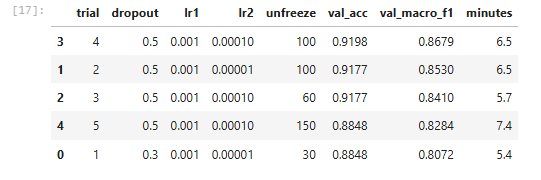

Fine-tuning about 100 layers worked best. Unfreezing too few layers (30) limited adaptation to this domain, while unfreezing too many (150) with a relatively high learning rate gave lower validation F1, possibly through overfitting or disturbing the pretrained features. With 100 unfrozen layers, the higher fine-tuning rate (1e-4) beat 1e-5. Note that trial 1 differs from the others in both dropout and unfreezing depth, so its gap cannot be attributed to one factor alone.

Accuracy vs. efficiency. The tuned ResNet50V2 is the most accurate but also the largest (23.58M parameters) and the slowest to train (12.7 min). MobileNetV2 has about 10× fewer parameters and runs at 2.08 ms/img with a moderate loss in accuracy (test macro-F1 0.834 vs. 0.906). It would be a reasonable choice for mobile or edge deployment. EfficientNetB0 sits between them in size but did not beat the default ResNet50V2 on test accuracy. Inference time for all pretrained models is only 2–4 ms per image, so for a web demo the accuracy gain of ResNet50V2 outweighs its extra cost.

Per-class performance of the best model (test set). Gingivitis (F1 0.942) and Hypodontia (0.960) are the best-recognised classes. They are also the largest classes. The weakest are Caries (0.828) and Tooth Discoloration (0.862), the two smallest classes, with only 29 and 27 test images. Mouth Ulcer has perfect precision (1.000) but lower recall (0.875), so some ulcers are missed but those predicted are always correct.

4. Model selection

ResNet50V2 (tuned) was selected as the final model because it had the highest validation macro-F1 (0.879) and it also scored best on the test set (accuracy 0.932, macro-F1 0.906). It is the model used in the deployment app.

5. Limitations
Test support for minority classes is small (27–32 images), so per-class scores can shift noticeably with a few images, and small gaps between models (e.g. EfficientNetB0 vs. default ResNet50V2) should not be over-interpreted.
Only ResNet50V2 was tuned. The other models used default settings, so part of ResNet50V2’s advantage may come from the extra tuning effort.
Each model was trained once with a single seed, so run-to-run variance was not measured.
The strict de-duplication removed many images (including 1,510 with conflicting labels), which makes the evaluation more honest but reduces the dataset size. The remaining label noise in the public dataset may also limit accuracy.
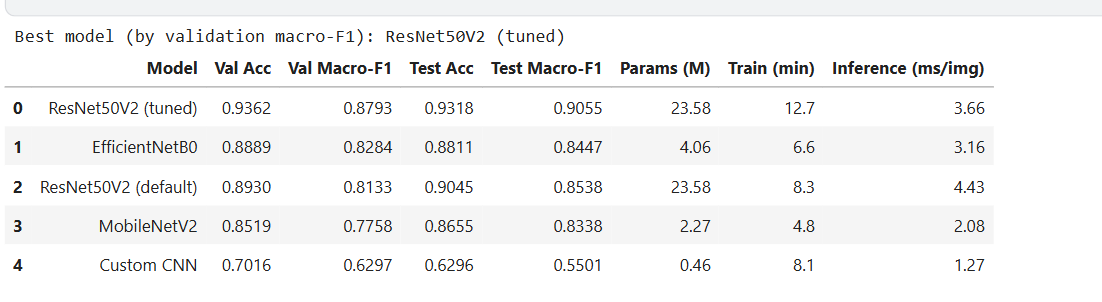